In [5]:
from langgraph.graph import MessagesState, StateGraph, START
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage
from langgraph.checkpoint.memory import InMemorySaver

In [6]:
load_dotenv()

True

In [7]:
chat_model = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash"
)

In [8]:
class ChatState(MessagesState):
    summary: str

In [9]:
def summarize_conversation(state: ChatState):

    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = chat_model.invoke(messages_for_summary)

    # Keep only last 2 messages verbatim
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete],
    }

In [10]:
def chat_node(state: ChatState):
    messages = []

    if state["summary"]:
        messages.append({
            "role": "system",
            "content": f"Conversation summary:\n{state['summary']}"
        })

    messages.extend(state["messages"])

    print(messages)

    response = chat_model.invoke(messages)
    return {"messages": [response]}

In [11]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [12]:
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)
builder.add_node("summarize", summarize_conversation)

builder.add_edge(START, "chat")

builder.add_conditional_edges(
    "chat",
    should_summarize,
    {
        True: "summarize",
        False: "__end__",
    }
)

builder.add_edge("summarize", "__end__")

In [13]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

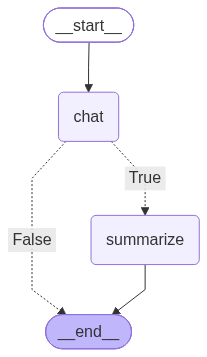

In [14]:
graph

In [15]:
config = {"configurable": {"thread_id": "t1"}}

def run_turn(text: str):
    out = graph.invoke({"messages": [HumanMessage(content=text)], "summary": ""}, config=config)
    return out

In [16]:
# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [17]:
run_turn('Quantum Physics')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='c6635789-0c83-4997-b497-f90b923b21de')]

--- STATE ---
summary: 
num_messages: 2
messages:
- HumanMessage : Quantum Physics
- AIMessage : Quantum Physics is a branch of physics that deals with the behavior of matter an


In [18]:
run_turn('How is Albert Einstien related?')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='c6635789-0c83-4997-b497-f90b923b21de'), AIMessage(content='Quantum Physics is a branch of physics that deals with the behavior of matter and energy at the atomic and subatomic levels. It\'s a foundational theory that completely revolutionized our understanding of the universe, replacing classical physics as the most accurate description of reality at very small scales.\n\nHere are some of the key concepts and reasons why it\'s so fascinating (and often counter-intuitive):\n\n1.  **Quantization of Energy:** One of the most fundamental ideas is that energy, momentum, angular momentum, and other quantities are not continuous but come in discrete "packets" called **quanta**. For example, electrons in an atom can only exist in specific energy levels, not in between them. This is like a staircase where you can only stand on a step, not float in between.\n\n2.  **Wave-Particle Duality:** Quantum mechanics

In [19]:
run_turn('What are some of Einstien"s fampus work')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='c6635789-0c83-4997-b497-f90b923b21de'), AIMessage(content='Quantum Physics is a branch of physics that deals with the behavior of matter and energy at the atomic and subatomic levels. It\'s a foundational theory that completely revolutionized our understanding of the universe, replacing classical physics as the most accurate description of reality at very small scales.\n\nHere are some of the key concepts and reasons why it\'s so fascinating (and often counter-intuitive):\n\n1.  **Quantization of Energy:** One of the most fundamental ideas is that energy, momentum, angular momentum, and other quantities are not continuous but come in discrete "packets" called **quanta**. For example, electrons in an atom can only exist in specific energy levels, not in between them. This is like a staircase where you can only stand on a step, not float in between.\n\n2.  **Wave-Particle Duality:** Quantum mechanics

In [20]:
run_turn('Explain special theory of relativity')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='c6635789-0c83-4997-b497-f90b923b21de'), AIMessage(content='Quantum Physics is a branch of physics that deals with the behavior of matter and energy at the atomic and subatomic levels. It\'s a foundational theory that completely revolutionized our understanding of the universe, replacing classical physics as the most accurate description of reality at very small scales.\n\nHere are some of the key concepts and reasons why it\'s so fascinating (and often counter-intuitive):\n\n1.  **Quantization of Energy:** One of the most fundamental ideas is that energy, momentum, angular momentum, and other quantities are not continuous but come in discrete "packets" called **quanta**. For example, electrons in an atom can only exist in specific energy levels, not in between them. This is like a staircase where you can only stand on a step, not float in between.\n\n2.  **Wave-Particle Duality:** Quantum mechanics